# One PPV cube and its moments
Use the **viento_turbustat** kernel. Load one existing GSTools velocity/density pair, choose one emissivity contrast, and generate one PPV cube. No local Python modules or widget packages are required.

Edit the inputs, then **Run All**. The FITS arrays are assumed to have NumPy axis order `(X, Y, Z)`, as in your generation workflow. This notebook computes moments 0 and 1 only. It does not generate new GSTools base fields.


In [23]:
from pathlib import Path
from time import perf_counter
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.constants import m_p, k_B
from astropy.io import fits
from turbustat.simulator import make_ppv
from spectral_cube import SpectralCube


In [30]:
# All editable inputs
velocity_path = Path("cubes/N64_L16/stable_alpha1.5_3d_velocity_N64_L16.fits")
density_path = Path("cubes/N64_L16/stable_alpha1.5_3d_density_N64_L16.fits")

sig_E = 0.0
velocity_scale_kms = 1.0  # Multiplier; does not force a particular velocity std.
los_axis = 0              # 0=X, 1=Y, 2=Z in the input arrays.
temperature_K = 10000.0
particle_mass_mp = 1.0
los_length_pc = 1.0
channel_width_kms = 0.25
v_min_kms = -20.0
v_max_kms = 20.0

# Inspection: None selects the central channel / central map pixel.
channel_index = None
pixel_row = None
pixel_col = None

# Optional export beside the input FITS cubes; rerunning overwrites this prefix.
save_outputs = True
output_dir = velocity_path.parent
output_prefix = "single_run"


In [31]:
# Load the two base fields as native float64 arrays.
with fits.open(velocity_path) as hdul:
    velocity_base = np.array(hdul[0].data, dtype=np.float64, order="C", copy=True)
    header_velocity = hdul[0].header.copy()
with fits.open(density_path) as hdul:
    density_base = np.array(hdul[0].data, dtype=np.float64, order="C", copy=True)
    header_density = hdul[0].header.copy()

if velocity_base.ndim != 3 or velocity_base.shape != density_base.shape:
    raise ValueError("Inputs must be 3D arrays with identical shapes.")
if min(velocity_base.shape) < 2:
    raise ValueError("Each input axis must have at least two samples.")
if not (np.isfinite(velocity_base).all() and np.isfinite(density_base).all()):
    raise ValueError("Input arrays must contain only finite values.")
if los_axis not in (0, 1, 2):
    raise ValueError("los_axis must be 0, 1, or 2.")
for header, role in ((header_velocity, "velocity"), (header_density, "density")):
    if header.get("ARRORDER", "XYZ") != "XYZ":
        raise ValueError("This notebook expects input array order XYZ.")
    if "FIELD" in header and header["FIELD"].strip().lower() != role:
        raise ValueError(f"Wrong FIELD for {role} input.")
# Check shared geometry if supplied by the base-field headers.
for key in ("DX", "DY", "DZ", "LSCALE_X", "LSCALE_Y", "LSCALE_Z",
            "ANGLE_X", "ANGLE_Y", "ANGLE_Z"):
    if key in header_velocity and key in header_density:
        if not np.isclose(header_velocity[key], header_density[key]):
            raise ValueError(f"Input geometry differs: {key}")

values = [sig_E, velocity_scale_kms, temperature_K, particle_mass_mp,
          los_length_pc, channel_width_kms, v_min_kms, v_max_kms]
if not np.isfinite(values).all():
    raise ValueError("Physical and spectral inputs must be finite.")
if min(temperature_K, particle_mass_mp, los_length_pc, channel_width_kms) <= 0:
    raise ValueError("Temperature, mass, depth, and channel width must be positive.")
if v_min_kms >= v_max_kms:
    raise ValueError("v_min_kms must be smaller than v_max_kms.")

density_std = density_base.std()
if density_std == 0:
    raise ValueError("Cannot standardize a constant density-base field.")
density_norm = (density_base - density_base.mean()) / density_std
velocity_64 = u.Quantity(
    np.ascontiguousarray(velocity_base * velocity_scale_kms), unit=u.km/u.s)
emissivity_relative = np.exp(sig_E * density_norm)
emissivity_relative /= emissivity_relative.mean()
if not (np.isfinite(emissivity_relative).all() and (emissivity_relative > 0).all()):
    raise ValueError("Emissivity must be finite and positive.")
emissivity_64 = u.Quantity(
    np.ascontiguousarray(emissivity_relative), unit=u.cm**-3)
temperature = temperature_K * u.K
particle_mass = particle_mass_mp * m_p
sigma_thermal = np.sqrt(k_B * temperature / particle_mass).to(u.km/u.s)

print("Input shape:", velocity_base.shape)
print("Velocity mean/std:", velocity_64.mean(), velocity_64.std())
print("Emissivity mean:", emissivity_relative.mean())
print("Std(log emissivity):", np.log(emissivity_relative).std())
print("Thermal dispersion:", sigma_thermal)


Input shape: (64, 64, 64)
Velocity mean/std: 0.14423516172796544 km / s 1.004965791893882 km / s
Emissivity mean: 1.0
Std(log emissivity): 0.0
Thermal dispersion: 9.085372725829808 km / s


In [40]:
# Generate exactly one PPV cube.
start = perf_counter()
cube_hdu = make_ppv(
    velocity_64, emissivity_64,
    los_axis=los_axis,
    #m=particle_mass,
    T=temperature,
#    los_length=los_length_pc * u.pc,
    chan_width=channel_width_kms * u.km/u.s,
    v_min=v_min_kms * u.km/u.s,
    v_max=v_max_kms * u.km/u.s,
    threads=1,
)
cube = SpectralCube.read(cube_hdu).with_spectral_unit(u.km/u.s)
moment0 = cube.moment0()
moment1 = cube.moment1()
sb = moment0.value
vv = moment1.value
if not (np.isfinite(sb).all() and (sb > 0).all() and np.isfinite(vv).all()):
    raise ValueError("Moment maps contain invalid pixels; inspect the spectral range.")
sb_normalized = sb / sb.max()
sig = float(vv.std())
sig2 = float(vv.var())

print(f"Completed in {perf_counter() - start:.2f} s")
print("PPV shape (channel, row, column):", cube.shape)
print("PPV intensity unit:", cube.unit)
print("Channel centers:", cube.spectral_axis[0], "to", cube.spectral_axis[-1])
if cube.shape[0] > 1:
    print("Channel spacing:", cube.spectral_axis[1] - cube.spectral_axis[0])
print(f"Centroid-map std: {sig:.6f} km/s; variance: {sig2:.6f} (km/s)^2")


Completed in 14.77 s
PPV shape (channel, row, column): (160, 64, 64)
PPV intensity unit: K
Channel centers: -19.87499999998891 km / s to 19.87500000001109 km / s
Channel spacing: 0.25 km / s
Centroid-map std: 0.568097 km/s; variance: 0.322735 (km/s)^2


In [41]:
# Direct line-of-sight comparison: M0 morphology and M1 centroid.
sb_direct = emissivity_relative.sum(axis=los_axis)
vv_direct = (emissivity_relative * velocity_64.value).sum(axis=los_axis) / sb_direct
if sb.shape != sb_direct.shape:
    raise ValueError("PPV and direct maps have different shapes.")
d0 = sb / sb.mean() - sb_direct / sb_direct.mean()
d1 = vv - vv_direct
print("M0 normalized RMS difference:", np.sqrt(np.mean(d0**2)))
print("M1 RMS difference (km/s):", np.sqrt(np.mean(d1**2)))
# M0 comparison removes the intensity conversion, so it does not test absolute flux.


M0 normalized RMS difference: 0.00040196941790470223
M1 RMS difference (km/s): 0.04621350780973553


## Inspect the cube and maps
The channel image and moment maps use the same row/column orientation. For input LOS=X, rows correspond to Y and columns to Z. Change the channel or pixel inputs and rerun this plotting cell to inspect the existing cube without generating it again. Change physical parameters and rerun from the input-loading cell onward.


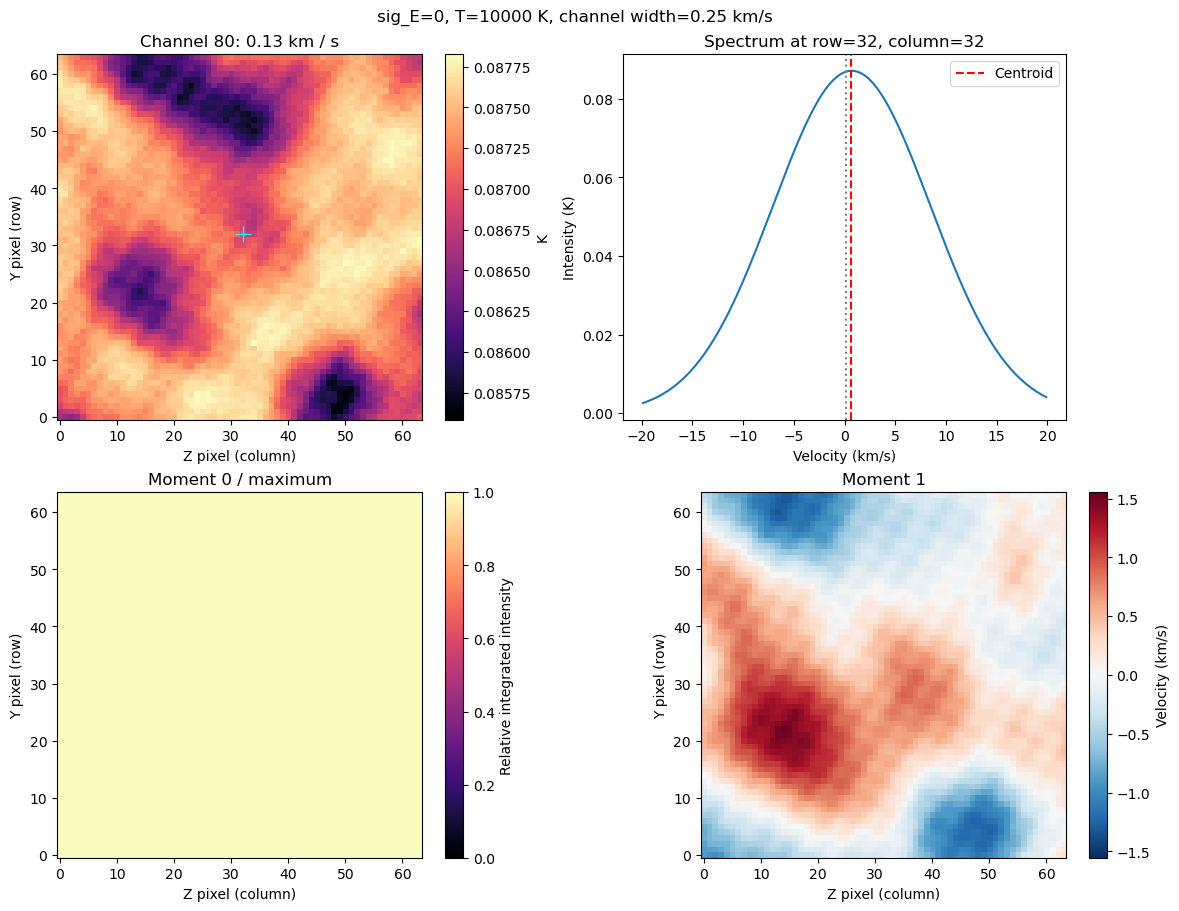

In [42]:
nchan, nrow, ncol = cube.shape
k = nchan // 2 if channel_index is None else int(channel_index)
row = nrow // 2 if pixel_row is None else int(pixel_row)
col = ncol // 2 if pixel_col is None else int(pixel_col)
if not (0 <= k < nchan and 0 <= row < nrow and 0 <= col < ncol):
    raise ValueError("Channel or pixel index is outside the cube.")

sky_axes = [axis for axis in "XYZ" if axis != "XYZ"[los_axis]]
xlabel = f"{sky_axes[1]} pixel (column)"
ylabel = f"{sky_axes[0]} pixel (row)"
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
ax = axes[0, 0]
im = ax.imshow(cube[k].value, origin="lower", cmap="magma")
ax.plot(col, row, "+", color="cyan", markersize=12)
fig.colorbar(im, ax=ax, label=str(cube.unit))
ax.set(title=f"Channel {k}: {cube.spectral_axis[k]:.2f}", xlabel=xlabel, ylabel=ylabel)

ax = axes[0, 1]
ax.plot(cube.spectral_axis.value, cube[:, row, col].value)
ax.axvline(cube.spectral_axis[k].value, color="gray", linestyle=":")
ax.axvline(vv[row, col], color="red", linestyle="--", label="Centroid")
ax.set(title=f"Spectrum at row={row}, column={col}",
       xlabel="Velocity (km/s)", ylabel=f"Intensity ({cube.unit})")
ax.legend()

ax = axes[1, 0]
im = ax.imshow(sb_normalized, origin="lower", cmap="magma", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label="Relative integrated intensity")
ax.set(title="Moment 0 / maximum", xlabel=xlabel, ylabel=ylabel)
ax = axes[1, 1]
vlim = max(float(np.max(np.abs(vv))), 1e-12)
im = ax.imshow(vv, origin="lower", cmap="RdBu_r", vmin=-vlim, vmax=vlim)
fig.colorbar(im, ax=ax, label="Velocity (km/s)")
ax.set(title="Moment 1", xlabel=xlabel, ylabel=ylabel)
fig.suptitle(f"sig_E={sig_E:g}, T={temperature_K:g} K, channel width={channel_width_kms:g} km/s")
plt.show()


## Optional export
Set `save_outputs=True` to save the PPV FITS, a two-extension moments FITS, and the inspection JPG. Exports use a single configurable prefix and overwrite existing files with that prefix. This minimal notebook is for inspection; it does not reproduce the full production pipeline header.


In [43]:
if save_outputs:
    output_dir.mkdir(parents=True, exist_ok=True)
    metadata = fits.Header()
    metadata["SIGE"] = float(sig_E)
    metadata["LOSAXIS"] = int(los_axis)
    metadata["VSCALE"] = float(velocity_scale_kms)
    metadata["TEMP"] = float(temperature_K)
    metadata["MASSMP"] = float(particle_mass_mp)
    metadata["LOS_PC"] = float(los_length_pc)
    metadata["CHANWID"] = float(channel_width_kms)
    metadata["VMIN"] = float(v_min_kms)
    metadata["VMAX"] = float(v_max_kms)
    metadata["VELFILE"] = velocity_path.name
    metadata["DENFILE"] = density_path.name
    for key in ("MODEL", "M3D", "LSCALE_X", "LSCALE_Y", "LSCALE_Z"):
        if key in header_velocity:
            metadata[key] = header_velocity[key]
    if "SEED" in header_density:
        metadata["SEED1"] = header_density["SEED"]
    if "SEED" in header_velocity:
        metadata["SEED2"] = header_velocity["SEED"]
    metadata.add_history("Emissivity: exp(sig_E * standardized density), mean normalized to 1.")
    cube_hdu.header.update(metadata)
    ppv_path = output_dir / f"{output_prefix}_ppv.fits"
    cube_hdu.writeto(ppv_path, overwrite=True)

    metadata["SIG"] = (sig, "Centroid-map std in km/s")
    metadata["SIG2"] = (sig2, "Centroid-map variance in (km/s)^2")
    metadata["PC"] = 1.0
    metadata["PIX"] = 1.0
    metadata["BINSIZE"] = 0
    metadata["BOX_SIZE"] = (float(np.hypot(*vv.shape)), "Map footprint diagonal in pixels")
    h0 = moment0.header.copy()
    h0["BUNIT"] = "1"
    h0["NORM"] = "MAX"
    h0["NORMFAC"] = float(sb.max())
    h0["ORIGUNIT"] = str(moment0.unit)
    moments_path = output_dir / f"{output_prefix}_moments.fits"
    fits.HDUList([
        fits.PrimaryHDU(header=metadata),
        fits.ImageHDU(sb_normalized, header=h0, name="MOM0"),
        fits.ImageHDU(vv, header=moment1.header.copy(), name="MOM1"),
    ]).writeto(moments_path, overwrite=True)
    figure_path = output_dir / f"{output_prefix}_inspection.jpg"
    fig.savefig(figure_path, dpi=200, facecolor="white")
    print("Saved:", ppv_path, moments_path, figure_path, sep="\n")
else:
    print("Inspection only. Set save_outputs=True to export.")


Saved:
cubes\N64_L16\single_run_ppv.fits
cubes\N64_L16\single_run_moments.fits
cubes\N64_L16\single_run_inspection.jpg
